# 15 — Day-30 Activity Codes with One-Hot Encoding and PCA

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## 1. Goal

Hank Butler's second recommendation was: *"Apply One-Hot Encoding followed by Principal Component Analysis (PCA) to
reduce activity-code dimensions."*

Notebooks 10–12 use only 15 selected activity codes, and notebook 14 grouped the codes. Here I instead use **every
activity code** seen in the training cases, and let PCA compress them into a few components. Three approaches are
compared with the same Logistic Regression:

- **A. Original:** 7 counts + 15 selected activity indicators (notebooks 10–12).
- **C. Combined:** A + activity-group indicators + progress feature (notebook 14).
- **D. PCA:** 7 counts + PCA components of all activity-code indicators, with **5, 10 or 20** components (fixed in advance).

Everything else is unchanged: historically completed cases, the recorded activity span, the 63-day threshold, day-30
eligibility (a retrospective rule), the random split (677 / 161) and the temporal split (617 / 168), and
`StandardScaler` + `LogisticRegression(max_iter=1000)` without tuning.

## 2. Load the Data and Build the Day-30 Cohort

In [1]:
import os
import warnings
from pathlib import Path

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
# hide only PM4Py's optional speed-up tip ("Install the optional requirement `r4pm` ..."); other warnings still show
warnings.filterwarnings("ignore", message="Install the optional requirement `r4pm`")

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# the project folder: works whether Jupyter starts in the notebooks folder or in the project folder
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_root / "data" / "raw" / "BPIC15_1.xes"



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

In [2]:
log = pm4py.read_xes(str(data_path))
df = pm4py.convert_to_dataframe(log)

case_data = df.groupby("case:concept:name").agg(
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)
case_data = case_data[case_data["end_date"].notna()]   # completed cases only
case_data["long_case"] = (case_data["duration_days"] > 63).astype(int)

case_data["prediction_time"] = case_data["first_event"] + pd.Timedelta(days=30)
active = case_data[case_data["last_event"] > case_data["prediction_time"]]

print("Completed cases:", len(case_data))
print("Day-30 eligible cases:", len(active))

Completed cases: 956
Day-30 eligible cases: 838


## 3. Shared Helpers (Copied Unchanged from Notebook 14)

These cells are exactly the code of notebook 14, so approaches A and C are rebuilt in the same way.

**Activity groups** (used only by approach C): the prefix of the code, with the first digit for `01_HOOFD`.

In [3]:
def add_activity_groups(events):
    # the group is the prefix of the activity code, e.g. "02_DRZ" from "02_DRZ_010"
    events = events.copy()
    events["activity_group"] = events["concept:name"].str.extract(r"^(\d{2}_[A-Z0-9]+)_")[0]

    # for the main process 01_HOOFD, add the first digit of the number: "01_HOOFD_065_1" -> "01_HOOFD_0xx"
    is_main = events["activity_group"] == "01_HOOFD"
    first_digit = events.loc[is_main, "concept:name"].str[9]   # "01_HOOFD_" has 9 characters
    events.loc[is_main, "activity_group"] = "01_HOOFD_" + first_digit + "xx"
    return events


grouped_log = add_activity_groups(df)
print("Activity codes:", grouped_log["concept:name"].nunique())
print("Activity groups:", grouped_log["activity_group"].nunique())
print("Events without a group:", grouped_log["activity_group"].isna().sum())

Activity codes: 398
Activity groups: 28
Events without a group: 0


**Keep only the events up to each case's day-30 cutoff.**

In [4]:
def events_by_day30(event_table, cases):
    # keep only events of the given cases that happened on or before that case's day-30 cutoff
    events = event_table[event_table["case:concept:name"].isin(cases.index)].copy()
    events["prediction_time"] = events["case:concept:name"].map(cases["prediction_time"])
    events["first_event"] = events["case:concept:name"].map(cases["first_event"])
    first30 = events[events["time:timestamp"] <= events["prediction_time"]].copy()
    first30["day"] = (first30["time:timestamp"] - first30["first_event"]).dt.total_seconds() / (24 * 60 * 60)
    return first30

**The seven count features** (two of them are exact combinations of others, kept for continuity).

In [5]:
count_columns = [
    "events_first30",
    "unique_activities_first30",
    "unique_resources_first30",
    "repeated_activities_first30",
    "events_first15",
    "events_days16_30",
    "days_since_last_event",
]


def count_features(first30, cases):
    first30 = first30.copy()
    first30["in_first15"] = first30["day"] <= 15
    features = first30.groupby("case:concept:name").agg(
        events_first30=("concept:name", "size"),
        unique_activities_first30=("concept:name", "nunique"),
        unique_resources_first30=("org:resource", "nunique"),
        events_first15=("in_first15", "sum"),
        last_event_by_day30=("time:timestamp", "max"),
    )
    features["repeated_activities_first30"] = features["events_first30"] - features["unique_activities_first30"]
    features["events_days16_30"] = features["events_first30"] - features["events_first15"]
    features["days_since_last_event"] = (
        cases.loc[features.index, "prediction_time"] - features["last_event_by_day30"]
    ).dt.total_seconds() / (24 * 60 * 60)
    return features[count_columns]

**Apply the helpers** to all eligible cases and check that no event after the cutoff was used.

In [6]:
first30 = add_activity_groups(events_by_day30(df, active))
counts = count_features(first30, active)
y = active.loc[counts.index, "long_case"]

print("Events recorded by day 30:", len(first30))
print("Latest event used, in days after the case start:", first30["day"].max())
print("Every event used is on or before its case's cutoff:", (first30["time:timestamp"] <= first30["prediction_time"]).all())
print("Activity groups recorded by day 30:", first30["activity_group"].nunique())

Events recorded by day 30: 14551
Latest event used, in days after the case start: 30.0
Every event used is on or before its case's cutoff: True
Activity groups recorded by day 30: 23


**The 15 original activity indicators** (selected on training cases only).

In [7]:
def select_activities(first30, case_ids):
    # activity codes recorded in 10-90% of the given cases, at most 15, most frequent first (ties by code)
    events = first30[first30["case:concept:name"].isin(case_ids)]
    share = events.groupby("concept:name")["case:concept:name"].nunique() / len(case_ids) * 100
    share = share.rename("train_cases_pct").reset_index()
    share = share[(share["train_cases_pct"] >= 10) & (share["train_cases_pct"] <= 90)]
    share = share.sort_values(["train_cases_pct", "concept:name"], ascending=[False, True])
    return share.head(15)["concept:name"].tolist()


def activity_flags(first30, activities, case_ids):
    # 1 if the activity was recorded by day 30 in that case, otherwise 0
    flags = pd.DataFrame(index=case_ids)
    for activity in activities:
        cases_with_activity = first30.loc[first30["concept:name"] == activity, "case:concept:name"].unique()
        flags["act_" + activity] = flags.index.isin(cases_with_activity).astype(int)
    return flags

**The group indicators and the progress feature** from notebook 14 (selected on training cases only).

In [8]:
def select_groups(first30, case_ids):
    # activity groups recorded by day 30 in at least 5% of the given cases, except 01_HOOFD_0xx
    events = first30[first30["case:concept:name"].isin(case_ids)]
    share = events.groupby("activity_group")["case:concept:name"].nunique() / len(case_ids) * 100
    groups = share[share >= 5].index.tolist()
    groups.remove("01_HOOFD_0xx")
    return sorted(groups)

In [9]:
def group_flags(first30, groups, case_ids):
    # 1 if the group was recorded by day 30 in that case, otherwise 0
    flags = pd.DataFrame(index=case_ids)
    for group in groups:
        cases_with_group = first30.loc[first30["activity_group"] == group, "case:concept:name"].unique()
        flags["grp_" + group] = flags.index.isin(cases_with_group).astype(int)

    # every rare group (not selected and not 01_HOOFD_0xx) goes into one column
    rare_events = first30[~first30["activity_group"].isin(groups + ["01_HOOFD_0xx"])]
    flags["grp_other_group"] = flags.index.isin(rare_events["case:concept:name"].unique()).astype(int)
    return flags

In [10]:
def highest_main_stage(first30, case_ids):
    # highest first digit of a 01_HOOFD code recorded by day 30, e.g. 4 for "01_HOOFD_4xx"
    main_events = first30[first30["activity_group"].str.startswith("01_HOOFD_")]
    stages = main_events["activity_group"].str[9].astype(int)
    highest = stages.groupby(main_events["case:concept:name"]).max()
    return highest.reindex(case_ids).fillna(0).astype(int).rename("highest_main_stage")

**Feature tables for A and C**, and the same model and scores as notebook 14.

In [11]:
def make_X(case_ids, approach, activities, groups):
    X = counts.loc[case_ids]
    if approach in ["A. Original", "C. Combined"]:
        X = X.join(activity_flags(first30, activities, case_ids))
    if approach in ["B. Grouped", "C. Combined"]:
        X = X.join(group_flags(first30, groups, case_ids))
        X = X.join(highest_main_stage(first30, case_ids))
    return X

In [12]:
def fit_logistic_regression(X_train, y_train):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)


def score(model, X, y_true):
    predictions = model.predict(X)
    return {
        "ROC-AUC": roc_auc_score(y_true, model.predict_proba(X)[:, 1]),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions),
        "Cases flagged long": int(predictions.sum()),
    }

## 4. One-Hot Encoding of the Activity Codes

**One-hot encoding** turns a category into 0/1 columns: one column per possible value. Each event has one activity code,
so one-hot encoding an event gives a 1 in its code's column. A **case** has many events, so I combine its events: the
column is 1 if that code was recorded **at least once by day 30**, otherwise 0. These are the same 0/1 indicators as in
approach A; the only difference is that now **every** code seen in the training cases gets a column, not just 15.

- The **vocabulary** (the list of columns) is taken from the **training cases only**, and again inside every
  cross-validation fold.
- A code that appears only in validation or test cases has no column, so it is simply ignored (no error).
- Only activity codes are encoded. Resource (staff) IDs are **not** encoded.

In [13]:
def select_vocabulary(first30, case_ids):
    # every activity code recorded by day 30 in at least one of the given (training) cases
    events = first30[first30["case:concept:name"].isin(case_ids)]
    return sorted(events["concept:name"].unique())

**One-hot encode, then combine per case.** `pd.get_dummies` gives one 0/1 column per activity code and one row per
event. Taking the maximum per case gives 1 if the code was recorded at least once by day 30. `reindex` keeps exactly the
training vocabulary: codes not seen in training are dropped, and vocabulary codes a case does not have become 0.

In [14]:
def activity_indicators(first30, vocabulary, case_ids):
    events = first30[first30["case:concept:name"].isin(case_ids)]
    one_hot = pd.get_dummies(events["concept:name"], dtype=int)    # one row per event, one column per code
    one_hot["case"] = events["case:concept:name"].values
    per_case = one_hot.groupby("case").max()                        # 1 if the code was recorded by day 30
    return per_case.reindex(index=case_ids, columns=vocabulary, fill_value=0)

## 5. PCA on the Activity Indicators

**PCA** (principal component analysis) finds a few new columns, called *components*, that keep as much of the variation
of the many 0/1 columns as possible. Each component is a weighted mix of activity codes. Components are only a
compression; I do not give them any real-world meaning.

The helper below does everything for one training group and one other group (validation or test):

1. build the vocabulary on the training cases;
2. build the 0/1 indicators for both groups with that vocabulary;
3. **fit PCA on the training indicators only**, then transform both groups with the fitted PCA;
4. put the 7 count features (outside PCA) next to the components.

`svd_solver="full"` makes PCA give exactly the same result every time.

In [15]:
def pca_features(train_ids, other_ids, n_components):
    vocabulary = select_vocabulary(first30, train_ids)
    train_indicators = activity_indicators(first30, vocabulary, train_ids)
    other_indicators = activity_indicators(first30, vocabulary, other_ids)

    pca = PCA(n_components=n_components, svd_solver="full").fit(train_indicators)   # training cases only

    component_names = ["pc_" + str(number) for number in range(1, n_components + 1)]
    train_components = pd.DataFrame(pca.transform(train_indicators), index=train_ids, columns=component_names)
    other_components = pd.DataFrame(pca.transform(other_indicators), index=other_ids, columns=component_names)

    X_train = counts.loc[train_ids].join(train_components)
    X_other = counts.loc[other_ids].join(other_components)
    return X_train, X_other, pca

## 6. The Two Splits (Same as Notebooks 10–14)

In [16]:
day14_cases = case_data[case_data["last_event"] > case_data["first_event"] + pd.Timedelta(days=14)]
original_train_ids, original_test_ids = train_test_split(
    day14_cases.index, test_size=0.20, random_state=42, stratify=day14_cases["long_case"]
)

random_train_ids = [case for case in original_train_ids if case in active.index]
random_test_ids = [case for case in original_test_ids if case in active.index]

print("Random training cases:", len(random_train_ids), "| long:", y.loc[random_train_ids].sum())
print("Random test cases:", len(random_test_ids), "| long:", y.loc[random_test_ids].sum())
print("Overlap:", len(set(random_train_ids) & set(random_test_ids)))

Random training cases: 677 | long: 377
Random test cases: 161 | long: 95
Overlap: 0


In [17]:
sorted_cases = active.sort_values("prediction_time", kind="stable")
boundary = sorted_cases["prediction_time"].iloc[int(len(sorted_cases) * 0.8)]

temporal_test = sorted_cases[sorted_cases["prediction_time"] >= boundary]
candidates = sorted_cases[sorted_cases["prediction_time"] < boundary]
temporal_train = candidates[(candidates["last_event"] < boundary) & (candidates["end_date"] < boundary)]
temporal_train_ids, temporal_test_ids = temporal_train.index, temporal_test.index

print("Boundary:", boundary)
print("Temporal training cases:", len(temporal_train_ids), "| long:", y.loc[temporal_train_ids].sum())
print("Temporal test cases:", len(temporal_test_ids), "| long:", y.loc[temporal_test_ids].sum())
print("Overlap:", len(set(temporal_train_ids) & set(temporal_test_ids)))

Boundary: 2013-10-25 22:00:00+00:00
Temporal training cases: 617 | long: 328
Temporal test cases: 168 | long: 100
Overlap: 0


## 7. Are 5, 10 and 20 Components Valid?

PCA can have at most as many components as the smaller of (number of training cases, number of indicator columns).
I check this for every cross-validation training part and both final training groups.

In [18]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_index = pd.Index(random_train_ids)   # lets us turn fold positions into case IDs
component_counts = [5, 10, 20]

fold_parts = list(folds.split(train_index, y.loc[train_index]))
training_groups = {"random training": train_index, "temporal training": temporal_train_ids}
for fold, (fit_positions, val_positions) in enumerate(fold_parts, start=1):
    training_groups[f"fold {fold} training part"] = train_index[fit_positions]

for name, ids in training_groups.items():
    vocabulary_size = len(select_vocabulary(first30, ids))
    limit = min(len(ids), vocabulary_size)
    print(f"{name:<22} cases {len(ids)} | activity codes {vocabulary_size} | max components {limit} | "
          f"5, 10, 20 valid: {max(component_counts) <= limit}")

random training        cases 677 | activity codes 209 | max components 209 | 5, 10, 20 valid: True
temporal training      cases 617 | activity codes 189 | max components 189 | 5, 10, 20 valid: True
fold 1 training part   cases 541 | activity codes 205 | max components 205 | 5, 10, 20 valid: True
fold 2 training part   cases 541 | activity codes 190 | max components 190 | 5, 10, 20 valid: True
fold 3 training part   cases 542 | activity codes 184 | max components 184 | 5, 10, 20 valid: True
fold 4 training part   cases 542 | activity codes 209 | max components 209 | 5, 10, 20 valid: True
fold 5 training part   cases 542 | activity codes 201 | max components 201 | 5, 10, 20 valid: True


### Explained variance on the random training cases

How much of the variation of the activity indicators the first components keep (PCA fitted on the 677 random training
cases only, with 20 components for this chart).

In [19]:
random_vocabulary = select_vocabulary(first30, random_train_ids)
random_indicators = activity_indicators(first30, random_vocabulary, random_train_ids)
chart_pca = PCA(n_components=20, svd_solver="full").fit(random_indicators)

explained = pd.Series(chart_pca.explained_variance_ratio_, index=range(1, 21))
cumulative = explained.cumsum()
print("Indicator columns (activity codes):", random_indicators.shape[1])
print("Cumulative explained variance with 5 / 10 / 20 components:",
      round(cumulative[5], 3), "/", round(cumulative[10], 3), "/", round(cumulative[20], 3))

Indicator columns (activity codes): 209
Cumulative explained variance with 5 / 10 / 20 components: 0.668 / 0.793 / 0.891


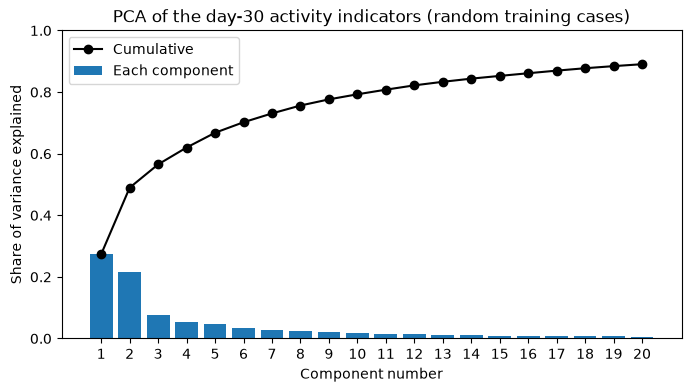

In [20]:
plt.figure(figsize=(8, 4))
plt.bar(explained.index, explained, label="Each component")
plt.plot(cumulative.index, cumulative, marker="o", color="black", label="Cumulative")
plt.xticks(range(1, 21))
plt.ylim(0, 1)
plt.xlabel("Component number")
plt.ylabel("Share of variance explained")
plt.title("PCA of the day-30 activity indicators (random training cases)")
plt.legend()
plt.show()

## 8. Decision Rules (Fixed Before Looking at the Test Sets)

1. For D, I use the component count (5, 10 or 20) with the **highest mean cross-validation ROC-AUC**.
2. Between A, C and the chosen D, I prefer the approach with the **highest mean cross-validation ROC-AUC**.

The test sets are not used for either choice.

## 9. Cross-Validation on the Random Training Cases

Same folds as notebooks 10–14. In every fold, the 15 activities, the groups, the vocabulary **and the PCA** are fitted
on that fold's training part only; the validation part is only transformed.

In [21]:
cv_rows = []
for fold, (fit_positions, val_positions) in enumerate(fold_parts, start=1):
    fit_ids = train_index[fit_positions]
    val_ids = train_index[val_positions]
    y_fit, y_val = y.loc[fit_ids], y.loc[val_ids]

    baseline = DummyClassifier(strategy="most_frequent").fit(counts.loc[fit_ids], y_fit)
    cv_rows.append({"Fold": fold, "Approach": "Majority baseline", **score(baseline, counts.loc[val_ids], y_val)})

    # A and C: selection on the fold's training part only
    activities = select_activities(first30, fit_ids)
    groups = select_groups(first30, fit_ids)
    for approach in ["A. Original", "C. Combined"]:
        model = fit_logistic_regression(make_X(fit_ids, approach, activities, groups), y_fit)
        cv_rows.append({"Fold": fold, "Approach": approach, **score(model, make_X(val_ids, approach, activities, groups), y_val)})

    # D: vocabulary and PCA fitted on the fold's training part only
    for n_components in component_counts:
        X_fit, X_val, pca = pca_features(fit_ids, val_ids, n_components)
        model = fit_logistic_regression(X_fit, y_fit)
        cv_rows.append({"Fold": fold, "Approach": f"D. PCA {n_components}", **score(model, X_val, y_val),
                        "Explained variance": pca.explained_variance_ratio_.sum()})

cv_results = pd.DataFrame(cv_rows)

**Cross-validation results.** The standard deviation shows how much the five folds differ; it is not a confidence interval.

In [22]:
cv_summary = cv_results.groupby("Approach")[["ROC-AUC", "Explained variance"]].agg(["mean", "std"])
cv_summary.round(3)

ROC-AUC        Explained variance       
                     mean    std               mean    std
Approach                                                  
A. Original         0.702  0.033                NaN    NaN
C. Combined         0.710  0.017                NaN    NaN
D. PCA 10           0.709  0.036              0.794  0.006
D. PCA 20           0.697  0.032              0.893  0.004
D. PCA 5            0.675  0.039              0.669  0.009
Majority baseline   0.500  0.000                NaN    NaN

In [23]:
cv_results.pivot(index="Fold", columns="Approach", values="ROC-AUC").round(3)

Approach,A. Original,C. Combined,D. PCA 10,D. PCA 20,D. PCA 5,Majority baseline
Fold,,,,,,
1,0.755,0.736,0.719,0.725,0.719,0.5
2,0.667,0.696,0.688,0.712,0.662,0.5
3,0.707,0.708,0.727,0.721,0.685,0.5
4,0.683,0.696,0.659,0.650,0.616,0.5
5,0.698,0.714,0.753,0.677,0.691,0.5


In [24]:
cv_roc = cv_results.groupby("Approach")["ROC-AUC"].mean()

pca_roc = cv_roc[["D. PCA 5", "D. PCA 10", "D. PCA 20"]]
best_pca = pca_roc.idxmax()
best_components = int(best_pca.split()[-1])

finalists = cv_roc[["A. Original", "C. Combined", best_pca]]
preferred = finalists.idxmax()

print("Mean cross-validation ROC-AUC:", cv_roc.round(3).to_dict())
print("Chosen PCA component count:", best_components)
print("Preferred approach among A, C and", best_pca + ":", preferred)

Mean cross-validation ROC-AUC: {'A. Original': 0.702, 'C. Combined': 0.71, 'D. PCA 10': 0.709, 'D. PCA 20': 0.697, 'D. PCA 5': 0.675, 'Majority baseline': 0.5}
Chosen PCA component count: 10
Preferred approach among A, C and D. PCA 10: C. Combined


## 10. Random Test and Temporal Test

A, C and the chosen D are fitted once on each training group and scored once on its test cases. For D, the vocabulary
and the PCA are fitted **separately** on the random training cases and on the temporal training cases; a fitted PCA is
never reused between the two.

In [25]:
def evaluate_split(train_ids, test_ids, split_name):
    results = {}
    y_train, y_test = y.loc[train_ids], y.loc[test_ids]

    baseline = DummyClassifier(strategy="most_frequent").fit(counts.loc[train_ids], y_train)
    results["Majority baseline"] = score(baseline, counts.loc[test_ids], y_test)

    activities = select_activities(first30, train_ids)
    groups = select_groups(first30, train_ids)
    for approach in ["A. Original", "C. Combined"]:
        model = fit_logistic_regression(make_X(train_ids, approach, activities, groups), y_train)
        results[approach] = score(model, make_X(test_ids, approach, activities, groups), y_test)

    X_train, X_test, pca = pca_features(train_ids, test_ids, best_components)
    model = fit_logistic_regression(X_train, y_train)
    results[best_pca] = {**score(model, X_test, y_test), "Explained variance": pca.explained_variance_ratio_.sum()}

    test_codes = set(first30.loc[first30["case:concept:name"].isin(test_ids), "concept:name"])
    unseen = test_codes - set(select_vocabulary(first30, train_ids))
    print(f"{split_name}: activity codes never seen in its training cases (ignored): {len(unseen)}")
    return pd.DataFrame(results).T

In [26]:
random_results = evaluate_split(random_train_ids, random_test_ids, "Random test")
temporal_results = evaluate_split(temporal_train_ids, temporal_test_ids, "Temporal test")

Random test: activity codes never seen in its training cases (ignored): 1


Temporal test: activity codes never seen in its training cases (ignored): 11


## 11. Check: A and C Reproduce Notebooks 10–14

Approaches A and C use the same code as notebook 14, so their results must match the outputs recorded there
(rounded to 3 decimals).

In [27]:
recorded = {
    ("A. Original", "cross-validation ROC-AUC"): 0.702, ("C. Combined", "cross-validation ROC-AUC"): 0.710,
    ("A. Original", "random ROC-AUC"): 0.659, ("C. Combined", "random ROC-AUC"): 0.708,
    ("A. Original", "temporal ROC-AUC"): 0.678, ("C. Combined", "temporal ROC-AUC"): 0.705,
    ("A. Original", "random precision"): 0.694, ("C. Combined", "random precision"): 0.730,
    ("A. Original", "temporal recall"): 0.550, ("C. Combined", "temporal recall"): 0.500,
}
current = {}
for approach in ["A. Original", "C. Combined"]:
    current[(approach, "cross-validation ROC-AUC")] = cv_roc[approach]
    current[(approach, "random ROC-AUC")] = random_results.loc[approach, "ROC-AUC"]
    current[(approach, "temporal ROC-AUC")] = temporal_results.loc[approach, "ROC-AUC"]
    current[(approach, "random precision")] = random_results.loc[approach, "Precision"]
    current[(approach, "temporal recall")] = temporal_results.loc[approach, "Recall"]

all_match = True
for key in recorded:
    match = abs(round(current[key], 3) - recorded[key]) < 0.0011
    all_match = all_match and match
    print(f"{key[0]:<13} {key[1]:<26} recorded {recorded[key]:.3f} | now {current[key]:.3f} | matches: {match}")
assert all_match, "A or C does not reproduce notebooks 10-14"

A. Original   cross-validation ROC-AUC   recorded 0.702 | now 0.702 | matches: True
C. Combined   cross-validation ROC-AUC   recorded 0.710 | now 0.710 | matches: True
A. Original   random ROC-AUC             recorded 0.659 | now 0.659 | matches: True
C. Combined   random ROC-AUC             recorded 0.708 | now 0.708 | matches: True
A. Original   temporal ROC-AUC           recorded 0.678 | now 0.678 | matches: True
C. Combined   temporal ROC-AUC           recorded 0.705 | now 0.705 | matches: True
A. Original   random precision           recorded 0.694 | now 0.694 | matches: True
C. Combined   random precision           recorded 0.730 | now 0.730 | matches: True
A. Original   temporal recall            recorded 0.550 | now 0.550 | matches: True
C. Combined   temporal recall            recorded 0.500 | now 0.500 | matches: True


## 12. Comparison Table

In [28]:
rows = ["Majority baseline", "A. Original", "C. Combined", best_pca]
comparison = pd.DataFrame({
    "CV ROC-AUC mean": cv_results.groupby("Approach")["ROC-AUC"].mean(),
    "CV ROC-AUC std": cv_results.groupby("Approach")["ROC-AUC"].std(),
    "Random ROC-AUC": random_results["ROC-AUC"],
    "Random precision": random_results["Precision"],
    "Random recall": random_results["Recall"],
    "Random flagged (of 161)": random_results["Cases flagged long"],
    "Temporal ROC-AUC": temporal_results["ROC-AUC"],
    "Temporal precision": temporal_results["Precision"],
    "Temporal recall": temporal_results["Recall"],
    "Temporal flagged (of 168)": temporal_results["Cases flagged long"],
}).loc[rows].astype(float)

comparison["Random flagged (of 161)"] = comparison["Random flagged (of 161)"].astype(int)
comparison["Temporal flagged (of 168)"] = comparison["Temporal flagged (of 168)"].astype(int)
comparison.round(3)

,CV ROC-AUC mean,CV ROC-AUC std,Random ROC-AUC,Random precision,Random recall,Random flagged (of 161),Temporal ROC-AUC,Temporal precision,Temporal recall,Temporal flagged (of 168)
Majority baseline,0.500,0.000,0.500,0.590,1.000,161,0.500,0.595,1.00,168
A. Original,0.702,0.033,0.659,0.694,0.716,98,0.678,0.775,0.55,71
C. Combined,0.710,0.017,0.708,0.730,0.768,100,0.705,0.847,0.50,59
D. PCA 10,0.709,0.036,0.721,0.716,0.768,102,0.729,0.828,0.53,64


In [29]:
print("Explained variance of the chosen PCA:")
print("  random training fit:  ", round(random_results.loc[best_pca, "Explained variance"], 3))
print("  temporal training fit:", round(temporal_results.loc[best_pca, "Explained variance"], 3))

Explained variance of the chosen PCA:
  random training fit:   0.793
  temporal training fit: 0.797


### ROC-AUC chart

The black error bars show **±1 standard deviation across the five folds** (not a confidence interval). The dashed line
is the majority baseline (0.50).

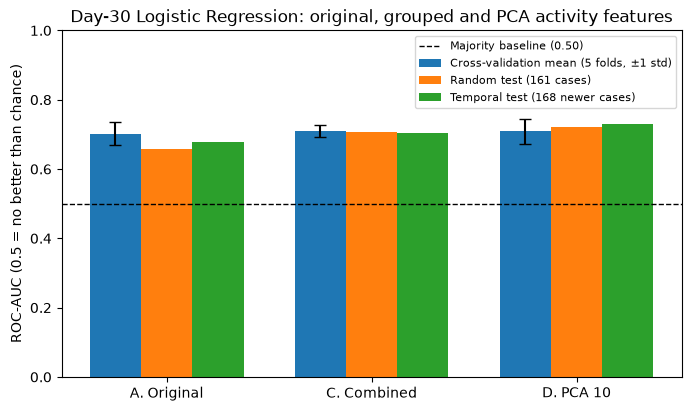

In [30]:
chart_rows = ["A. Original", "C. Combined", best_pca]
positions = [0, 1, 2]
width = 0.25

plt.figure(figsize=(8, 4.5))
plt.bar([p - width for p in positions], comparison.loc[chart_rows, "CV ROC-AUC mean"], width,
        yerr=comparison.loc[chart_rows, "CV ROC-AUC std"], capsize=4, label="Cross-validation mean (5 folds, ±1 std)")
plt.bar(positions, comparison.loc[chart_rows, "Random ROC-AUC"], width, label="Random test (161 cases)")
plt.bar([p + width for p in positions], comparison.loc[chart_rows, "Temporal ROC-AUC"], width,
        label="Temporal test (168 newer cases)")
plt.axhline(0.5, color="black", linestyle="--", linewidth=1, label="Majority baseline (0.50)")
plt.xticks(positions, chart_rows)
plt.ylim(0, 1)
plt.ylabel("ROC-AUC (0.5 = no better than chance)")
plt.title("Day-30 Logistic Regression: original, grouped and PCA activity features")
plt.legend(loc="upper right", fontsize=8)
plt.show()

## 13. Leakage Check

I change the activity and resource of **every event after each case's day-30 cutoff** to fake values (cohort and
cutoffs fixed) and rebuild the PCA input indicators, the count features and the PCA components with the same vocabulary
and the same fitted PCA. If the features only use events up to day 30, nothing may change.

In [31]:
changed = df.copy()
after_day30 = changed["time:timestamp"] > changed["case:concept:name"].map(active["prediction_time"])
changed.loc[after_day30, "concept:name"] = "FAKE_ACTIVITY"
changed.loc[after_day30, "org:resource"] = "FAKE_RESOURCE"
changed_first30 = add_activity_groups(events_by_day30(changed, active))
all_ids = list(counts.index)

In [32]:
original_indicators = activity_indicators(first30, random_vocabulary, all_ids)
changed_indicators = activity_indicators(changed_first30, random_vocabulary, all_ids)

original_components = chart_pca.transform(original_indicators)
changed_components = chart_pca.transform(changed_indicators)
changed_counts = count_features(changed_first30, active).loc[all_ids]

print("Events changed:", after_day30.sum())
print("PCA input indicators unchanged:", changed_indicators.equals(original_indicators))
print("PCA components unchanged:", (original_components == changed_components).all())
print("Count features unchanged:", changed_counts.equals(counts.loc[all_ids]))

Events changed: 26120
PCA input indicators unchanged: True
PCA components unchanged: True
Count features unchanged: True


**What this check shows, and what it does not.** Three separate questions:

1. **Feature timing:** the features use only events timestamped on or before day 30. The check above tests this in code.
2. **Retrospective cohort selection:** a case is included only if its last recorded event is after day 30, which is
   only known afterwards. The check does not change this.
3. **Real-world knowledge of open cases:** a live system would need to know which cases are really still open at
   day 30. This log does not show that reliably.

A successful leakage check does **not** solve limitations 2 and 3.

## 14. Interpretation

**Encoding and PCA.** The random training cases contain 209 different activity codes by day 30 (184–209 in the five
fold training parts, 189 in the temporal training cases), so 5, 10 and 20 components are valid everywhere. On the random
training cases, 5 components keep 66.8% of the variation of the indicators, 10 keep 79.3% and 20 keep 89.1%. The
components are a compression only; I do not interpret them.

**A and C reproduce notebooks 10–14 exactly**, so the comparison is fair.

**Choosing the component count (cross-validation only).** Mean cross-validation ROC-AUC: 0.675 with 5 components,
**0.709 with 10** and 0.697 with 20. Ten components are chosen. Five components lose too much information, and twenty
do not help further.

**Did PCA improve cross-validation?** No clear improvement. D with 10 components (0.709 ± 0.036) is practically equal to
C (0.710 ± 0.017) and slightly above A (0.702 ± 0.033). The differences are much smaller than the fold-to-fold variation,
and D varies more between folds (0.659 to 0.753) than C. By the rule fixed in advance, **C. Combined stays the preferred
approach**.

**Test sets (not used for any choice).** D has the highest ROC-AUC on both test sets: 0.721 on the random test (C 0.708,
A 0.659) and 0.729 on the temporal test (C 0.705, A 0.678). Because these test sets were already used in earlier notebooks
and the differences between C and D are small, this does not change the choice.

**Warnings are still unstable.** D flags 102 of 161 random-test cases (precision 0.716, recall 0.768) but only 64 of 168
temporal-test cases (precision 0.828, recall 0.53), so on the newer cases it still misses almost half of the long cases.

**Answer.** Using all activity codes through PCA gives a ranking signal of about the same size as the activity groups in
notebook 14: both are slightly better than the original 15 indicators on the tests, but neither shows a clear
cross-validation improvement. PCA also makes the features harder to explain, because each component mixes many codes.
The result is **exploratory**, and the model is still **not ready for operational use**.

## 15. Limitations

- The random and temporal test cases were **already used** during exploratory modelling in notebooks 07–14, so they are
  **not** independent final validations. 138 of the 168 temporal test cases were training cases in the random split.
- The cohort is retrospective, and the 63-day threshold was chosen with all completed cases (`01_EDA.ipynb`).
- PCA components are mixtures of many activity codes. They are a compression, **not** explanations or causes.
- Only Logistic Regression with fixed settings and three fixed component counts was tested.
- One Dutch municipality; not SPAR or Montenegro data.